# **ZTF Variable Stars:** Cross-Survey Classification

## Imports and Configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import FunctionTransformer

from gaia_variable_stars.config import (
    RAW_ROOT, INTERIM_ROOT, PROCESSED_ROOT, FEATURE_FILE,
    MODELS_ROOT, FIGURES_ROOT, CLASSES, MIN_POINTS, SEED, FOLDS,
)
from gaia_variable_stars.features import extract, MIN_PERIOD

REPEATS = 5
BOOTSTRAPS = 1500
MAX_FAP = 0.01
MAX_DRIFT = 0.25

OUTPUT = MODELS_ROOT / "ztf"
FIGURES = FIGURES_ROOT / "ztf"

OUTPUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)

## Load Data

In [2]:
sources = pd.read_csv(RAW_ROOT / "ztf_sources.csv")
observations = pd.read_csv(INTERIM_ROOT / "ztf_clean.csv")

gaia = pd.read_csv(FEATURE_FILE.with_name("gaia_features_fe.csv")).set_index("source_id")
validation = pd.read_csv(FEATURE_FILE.with_name("gaia_period_validation_fe.csv")).set_index("source_id")

cohort = pd.DataFrame({
    "gaia": sources.groupby("class_name").size(),
    "matched": sources.dropna(subset=["oid"]).groupby("class_name").size(),
    "eligible": sources.loc[sources["n_r_epochs"].ge(MIN_POINTS)].groupby("class_name").size(),
}).reindex(CLASSES).fillna(0).astype(int)

cohort["coverage"] = cohort["eligible"] / cohort["gaia"]

display(cohort.round(3))

,gaia,matched,eligible,coverage
class_name,,,,
RR Lyrae,478,191,175,0.366
Cepheid,500,73,70,0.140
Eclipsing Binary,500,232,226,0.452
Long-Period Variable,500,103,80,0.160


In [3]:
observations = observations.sort_values(["source_id", "time"])

records, light_curves = extract(observations)
ztf = pd.DataFrame(records).set_index("source_id")

ids = gaia.index.intersection(ztf.index[ztf["searchable"]]).sort_values()

gaia = gaia.loc[ids].copy()
ztf = ztf.loc[ids].copy()

stars = validation.loc[ids, ["class_name", "sky_cell", "gaia_period", "period_status", "period_estimate", "period_reliable"]].copy()

stars = stars.rename(columns={
    "period_status": "Gaia_status",
    "period_estimate": "Gaia_period",
    "period_reliable": "Gaia_reliable",
})

stars["ZTF_period"] = ztf["period_estimate"]
stars["ZTF_reliable"] = ztf["period_fap"].le(MAX_FAP)

display(stars["class_name"].value_counts().reindex(CLASSES))

class_name
RR Lyrae                175
Cepheid                  70
Eclipsing Binary        226
Long-Period Variable     80
Name: count, dtype: int64

## Period Recovery

In [4]:
estimate = ztf["period_estimate"]
reference = stars["gaia_period"]
span = ztf["time_span"]

eligible = reference.ge(MIN_PERIOD) & reference.le(ztf["search_max_period"])

exact = eligible & (span * (1 / estimate - 1 / reference).abs()).le(MAX_DRIFT)
half = eligible & ~exact & (span * (1 / estimate - 2 / reference).abs()).le(MAX_DRIFT)
double = eligible & ~exact & ~half & (span * (1 / estimate - 0.5 / reference).abs()).le(MAX_DRIFT)

stars["ZTF_status"] = np.select(
    [~eligible, exact, half, double],
    ["ineligible", "exact", "half", "double"],
    default="mismatch",
)

statuses = ["exact", "half", "double", "mismatch", "ineligible"]

for survey in ["Gaia", "ZTF"]:
    print(survey)
    display(pd.crosstab(stars["class_name"], stars[f"{survey}_status"])
            .reindex(index=CLASSES, columns=statuses, fill_value=0))

Gaia


Gaia_status,exact,half,double,mismatch,ineligible
class_name,,,,,
RR Lyrae,160,1,0,14,0
Cepheid,68,0,0,2,0
Eclipsing Binary,5,168,0,53,0
Long-Period Variable,48,0,0,20,12


ZTF


ZTF_status,exact,half,double,mismatch,ineligible
class_name,,,,,
RR Lyrae,93,0,0,82,0
Cepheid,55,0,0,15,0
Eclipsing Binary,2,127,0,97,0
Long-Period Variable,17,0,0,63,0


In [5]:
paired = stars.loc[stars["Gaia_status"].ne("ineligible") & stars["ZTF_status"].ne("ineligible")]

recovery = pd.DataFrame({
    "sources": paired.groupby("class_name").size(),
    **{
        f"{survey}_{status}": paired[f"{survey}_status"].eq(status).groupby(paired["class_name"]).mean()
        for survey in ["Gaia", "ZTF"] for status in statuses[:-1]
    },
    "Gaia_reliable": paired.groupby("class_name")["Gaia_reliable"].mean(),
    "ZTF_reliable": paired.groupby("class_name")["ZTF_reliable"].mean(),
}).reindex(CLASSES)

display(recovery.round(3))

,sources,Gaia_exact,Gaia_half,Gaia_double,Gaia_mismatch,ZTF_exact,ZTF_half,ZTF_double,ZTF_mismatch,Gaia_reliable,ZTF_reliable
class_name,,,,,,,,,,,
RR Lyrae,175,0.914,0.006,0.0,0.080,0.531,0.000,0.0,0.469,0.794,0.817
Cepheid,70,0.971,0.000,0.0,0.029,0.786,0.000,0.0,0.214,1.000,1.000
Eclipsing Binary,226,0.022,0.743,0.0,0.235,0.009,0.562,0.0,0.429,0.690,0.673
Long-Period Variable,68,0.706,0.000,0.0,0.294,0.176,0.000,0.0,0.824,0.882,0.838


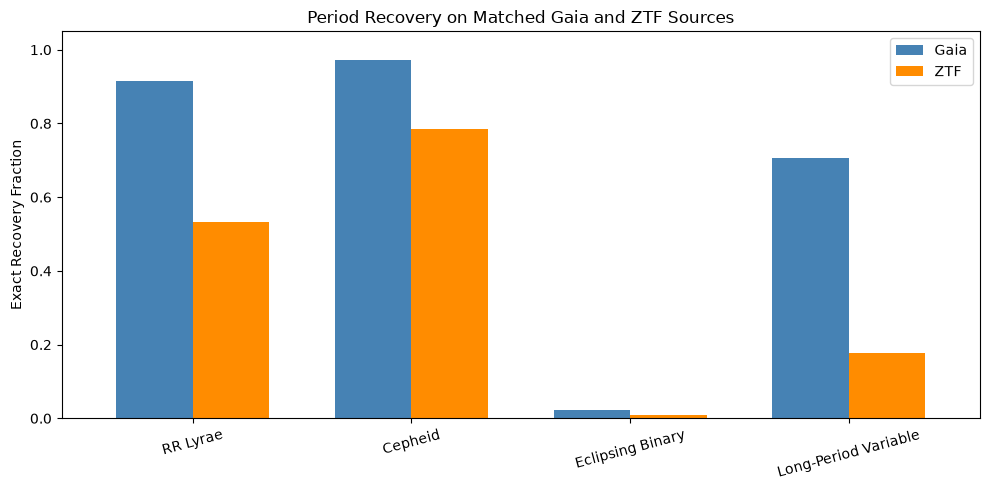

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))

recovery[["Gaia_exact", "ZTF_exact"]].plot.bar(
    ax=ax, color=["steelblue", "darkorange"], width=0.7
)

ax.set_title("Period Recovery on Matched Gaia and ZTF Sources")
ax.set_xlabel("")
ax.set_ylabel("Exact Recovery Fraction")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=15)
ax.legend(["Gaia", "ZTF"])

fig.tight_layout()
fig.savefig(FIGURES / "period_recovery.png", dpi=300, bbox_inches="tight")
plt.show()

## Feature Selection

In [7]:
shape = [
    "magnitude_std", "magnitude_skew", "magnitude_kurt",
    "magnitude_mad", "amplitude", "beyond_1sigma_fraction",
]

timescale = [
    "von_neumann_eta", "stetson_j", "sf_short",
    "sf_long", "sf_ratio", "max_visit_slope",
]

period = [
    "log_period", "power", "half_power", "double_power",
    "half_power_ratio", "double_power_ratio", "fourier_amp", "fourier_ratio",
]

free = shape + timescale
shared = free + period

ztf.loc[~stars["ZTF_reliable"], period] = np.nan

data = {
    "Gaia": gaia[shared].replace([np.inf, -np.inf], np.nan),
    "ZTF": ztf[shared].replace([np.inf, -np.inf], np.nan),
}

## Spatial Cross-Validation

In [8]:
labels = stars["class_name"].to_numpy()
sky = stars["sky_cell"].to_numpy()

splits = [
    list(StratifiedGroupKFold(
        n_splits=FOLDS, shuffle=True, random_state=SEED + 101 * repeat
    ).split(stars, labels, sky))
    for repeat in range(REPEATS)
]

folds = np.zeros((REPEATS, len(stars)), dtype=int)

print("Sources:", len(stars))
print("Sky Cells:", stars["sky_cell"].nunique())

Sources: 551
Sky Cells: 75


## Models

In [9]:
models = {
    "RF": Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
        ("model", RandomForestClassifier(
            n_estimators=250, min_samples_leaf=2,
            max_features="sqrt", random_state=SEED, n_jobs=-1,
        )),
    ]),

    "HGB": Pipeline([
        ("flags", FeatureUnion([
            ("values", FunctionTransformer()),
            ("missing", MissingIndicator(features="all", sparse=False)),
        ])),
        ("model", HistGradientBoostingClassifier(
            max_iter=250, learning_rate=0.05, min_samples_leaf=15,
            l2_regularization=1.0, random_state=SEED,
        )),
    ]),
}

## Cross-Survey Classification

In [10]:
features = {"full": shared, "period_free": free}

experiments = {
    ("Gaia", "full"): {"Gaia-Gaia": "Gaia", "Gaia-ZTF": "ZTF"},
    ("ZTF", "full"): {"ZTF-ZTF": "ZTF"},
    ("Gaia", "period_free"): {"Gaia-ZTF period-free": "ZTF"},
}

predictions = {
    (name, trial): np.empty((REPEATS, len(stars)), dtype=object)
    for name in models for targets in experiments.values() for trial in targets
}

for repeat, partition in enumerate(splits):
    for fold, (train, test) in enumerate(partition, start=1):
        folds[repeat, test] = fold

        if len(np.unique(labels[train])) != len(CLASSES):
            raise ValueError("A spatial training fold is missing a stellar class.")

        for name, model in models.items():
            for (origin, version), targets in experiments.items():
                cols = features[version]
                fitted = clone(model).fit(data[origin].iloc[train][cols], labels[train])

                for trial, target in targets.items():
                    predictions[name, trial][repeat, test] = fitted.predict(data[target].iloc[test][cols])

    print(f"Repeat {repeat + 1}/{REPEATS} complete")

Repeat 1/5 complete
Repeat 2/5 complete
Repeat 3/5 complete
Repeat 4/5 complete
Repeat 5/5 complete


## Classification Results

In [11]:
truth = pd.Categorical(labels, categories=CLASSES).codes
groups, cells = pd.factorize(sky, sort=True)
size = len(CLASSES)

def count(values):
    predicted = pd.Categorical(values.ravel(), categories=CLASSES).codes.reshape(values.shape)
    matrix = np.zeros((REPEATS, len(cells), size, size), dtype=int)

    for repeat in range(REPEATS):
        np.add.at(matrix[repeat], (groups, truth, predicted[repeat]), 1)

    return matrix


def score(matrix):
    correct = np.diagonal(matrix, axis1=-2, axis2=-1)
    support = matrix.sum(axis=-1)
    predicted = matrix.sum(axis=-2)

    accuracy = correct.sum(axis=-1) / support.sum(axis=-1)
    recall = (correct / support).mean(axis=-1)
    f1 = (2 * correct / (support + predicted)).mean(axis=-1)

    return np.stack([accuracy, recall, f1], axis=-1).mean(axis=-2)


matrices = {key: count(values) for key, values in predictions.items()}

rng = np.random.default_rng(SEED)
weights = rng.multinomial(len(cells), np.full(len(cells), 1 / len(cells)), size=BOOTSTRAPS)

support = np.zeros((len(cells), size), dtype=int)
np.add.at(support, (groups, truth), 1)

weights = weights[(weights @ support > 0).all(axis=1)]

points = {key: score(matrix.sum(axis=1)) for key, matrix in matrices.items()}
draws = {key: score(np.einsum("bc,rcij->brij", weights, matrix)) for key, matrix in matrices.items()}

In [12]:
metrics = ["accuracy", "balanced_accuracy", "macro_f1"]

def summarize(key):
    low, high = np.quantile(draws[key], [0.025, 0.975], axis=0)

    return {
        "model": key[0], "experiment": key[1],
        **dict(zip(metrics, points[key])),
        **dict(zip([f"{name}_lo" for name in metrics], low)),
        **dict(zip([f"{name}_hi" for name in metrics], high)),
    }


results = pd.DataFrame([summarize(key) for key in predictions])

display(results.round(4))

,model,experiment,accuracy,balanced_accuracy,macro_f1,accuracy_lo,balanced_accuracy_lo,macro_f1_lo,accuracy_hi,balanced_accuracy_hi,macro_f1_hi
0,RF,Gaia-Gaia,0.9448,0.9333,0.9362,0.9250,0.9087,0.9062,0.9677,0.9627,0.9611
1,RF,Gaia-ZTF,0.7456,0.6493,0.6807,0.6633,0.5859,0.5955,0.8097,0.7441,0.7564
2,RF,ZTF-ZTF,0.8483,0.8209,0.8390,0.7842,0.7547,0.7552,0.8884,0.8827,0.8804
3,RF,Gaia-ZTF period-free,0.6367,0.5002,0.4969,0.5237,0.4398,0.4082,0.7042,0.5914,0.5691
4,HGB,Gaia-Gaia,0.9412,0.9359,0.9330,0.9235,0.9136,0.8973,0.9672,0.9664,0.9635
5,HGB,Gaia-ZTF,0.7456,0.6815,0.6988,0.6669,0.6113,0.6027,0.8256,0.7787,0.7882
6,HGB,ZTF-ZTF,0.8581,0.8432,0.8534,0.8057,0.7808,0.7781,0.8962,0.9009,0.8952
7,HGB,Gaia-ZTF period-free,0.6098,0.4735,0.4583,0.5001,0.4079,0.3667,0.6922,0.5825,0.5382


## Paired Performance Differences

In [13]:
contrasts = {
    "Cross-survey change": ("Gaia-ZTF", "Gaia-Gaia"),
    "ZTF training improvement": ("ZTF-ZTF", "Gaia-ZTF"),
    "Period contribution": ("Gaia-ZTF", "Gaia-ZTF period-free"),
}

def compare(name, contrast, first, second):
    change = points[name, first][2] - points[name, second][2]
    low, high = np.quantile(draws[name, first][:, 2] - draws[name, second][:, 2], [0.025, 0.975])

    return {
        "model": name, "comparison": contrast,
        "macro_f1_change": change, "lower": low, "upper": high,
    }


differences = pd.DataFrame([
    compare(name, contrast, first, second)
    for name in models for contrast, (first, second) in contrasts.items()
])

display(differences.round(4))

,model,comparison,macro_f1_change,lower,upper
0,RF,Cross-survey change,-0.2555,-0.3426,-0.1765
1,RF,ZTF training improvement,0.1582,0.0925,0.2150
2,RF,Period contribution,0.1838,0.1385,0.2290
3,HGB,Cross-survey change,-0.2342,-0.3312,-0.1401
4,HGB,ZTF training improvement,0.1546,0.0792,0.2279
5,HGB,Period contribution,0.2405,0.2040,0.2814


## Class-Specific Recall

In [14]:
recall = pd.DataFrame([
    {
        "model": name, "experiment": trial,
        **dict(zip(CLASSES, np.diag(matrix.sum(axis=(0, 1))) / matrix.sum(axis=(0, 1, 3)))),
    }
    for (name, trial), matrix in matrices.items()
])

display(recall.round(4))

,model,experiment,RR Lyrae,Cepheid,Eclipsing Binary,Long-Period Variable
0,RF,Gaia-Gaia,0.9589,0.8686,0.9558,0.9500
1,RF,Gaia-ZTF,0.8686,0.4029,0.8531,0.4725
2,RF,ZTF-ZTF,0.8126,0.7771,0.9265,0.7675
3,RF,Gaia-ZTF period-free,0.8057,0.0543,0.7858,0.3550
4,HGB,Gaia-Gaia,0.9520,0.9057,0.9434,0.9425
5,HGB,Gaia-ZTF,0.8320,0.7000,0.8265,0.3675
6,HGB,ZTF-ZTF,0.8114,0.8486,0.9204,0.7925
7,HGB,Gaia-ZTF period-free,0.8046,0.0229,0.7416,0.3250


## Model Comparison

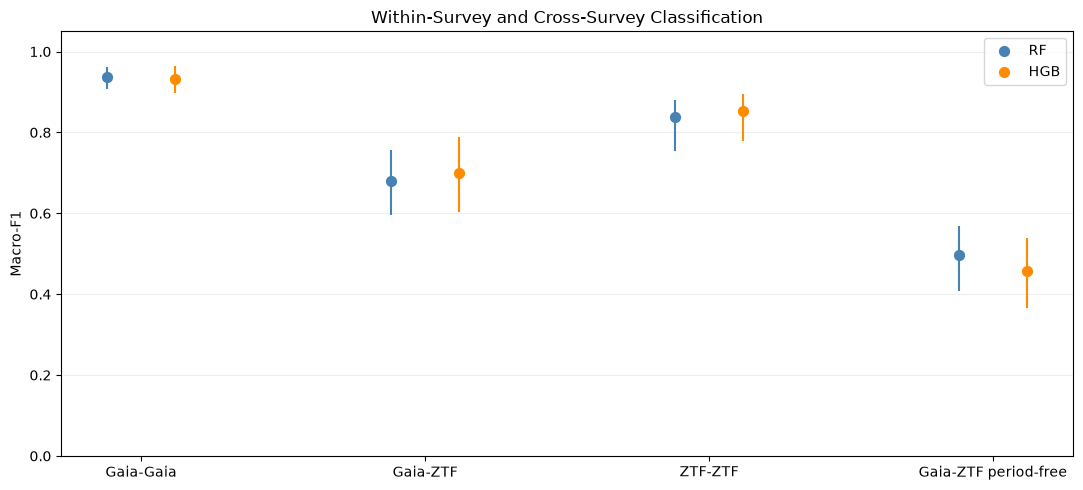

In [15]:
fig, ax = plt.subplots(figsize=(11, 5))

trials = results["experiment"].unique()
positions = np.arange(len(trials))

for name, offset, color in [("RF", -0.12, "steelblue"), ("HGB", 0.12, "darkorange")]:
    part = results.loc[results["model"].eq(name)].set_index("experiment").loc[trials]

    ax.scatter(positions + offset, part["macro_f1"], color=color, label=name, s=50)
    ax.vlines(positions + offset, part["macro_f1_lo"], part["macro_f1_hi"], color=color)

ax.set_title("Within-Survey and Cross-Survey Classification")
ax.set_ylabel("Macro-F1")
ax.set_xticks(positions, trials)
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.2)
ax.legend()

fig.tight_layout()
fig.savefig(FIGURES / "model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## Export Results

In [16]:
oof = pd.concat([
    stars[["class_name", "sky_cell", "Gaia_status", "ZTF_status"]].reset_index().assign(
        repeat=repeat + 1,
        fold=folds[repeat],
        **{f"{name}_{trial}": values[repeat] for (name, trial), values in predictions.items()},
    )
    for repeat in range(REPEATS)
], ignore_index=True)

cohort.to_csv(OUTPUT / "cohort.csv")
recovery.to_csv(OUTPUT / "period_recovery.csv")
stars.to_csv(OUTPUT / "period_validation.csv")

stars[["class_name", "sky_cell"]].join(data["ZTF"]).to_csv(PROCESSED_ROOT / "ztf_features.csv")

results.to_csv(OUTPUT / "results.csv", index=False)
differences.to_csv(OUTPUT / "differences.csv", index=False)
recall.to_csv(OUTPUT / "recall.csv", index=False)
oof.to_csv(OUTPUT / "predictions.csv", index=False)